<a href="https://colab.research.google.com/github/mrpunith-1920/gnn-fraud-detection/blob/main/06_results_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install torch_geometric

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 10.5 MB/s  0:00:00


In [3]:
!pip install torch_geometric

In [4]:
from google.colab import drive
drive.mount('/content/drive')

import torch, numpy as np, pandas as pd
import torch.nn.functional as F
from torch_geometric.nn import SAGEConv, GCNConv, GATConv
from sklearn.metrics import precision_score, recall_score, f1_score, average_precision_score, roc_auc_score

path = '/content/drive/MyDrive/gnn-project/data/elliptic_bitcoin_dataset/'
data = torch.load(path + 'elliptic_graph.pt', weights_only=False)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
data = data.to(device)
print(data, device)

Mounted at /content/drive


/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Data(x=[203769, 165], edge_index=[2, 234355], y=[203769], timestep=[203769], train_mask=[203769], test_mask=[203769]) cuda


In [5]:
runs = pd.read_csv(path + 'gnn_runs.csv')

In [6]:
import os
print(os.listdir(path))

['elliptic_txs_classes.csv', 'elliptic_txs_edgelist.csv', 'elliptic_txs_features.csv', 'elliptic_graph.pt', 'results_so_far.csv', 'gnn_runs.csv', 'gnn_summary.csv', 'layers_results.csv', 'graphsage.pth', 'gnn_bar.png', 'final_results.csv']


In [7]:
runs = pd.read_csv(path + 'gnn_runs.csv')
cols = ['Precision','Recall','F1','PR-AUC','ROC-AUC']
mean = runs.groupby('Model')[cols].mean()
std  = runs.groupby('Model')[cols].std()
print(mean.round(3))
print(std.round(3))
print(pd.read_csv(path + 'layers_results.csv'))

       Precision  Recall     F1  PR-AUC  ROC-AUC
Model                                           
GAT        0.657   0.618  0.636   0.526    0.902
GCN        0.484   0.528  0.504   0.516    0.839
SAGE       0.720   0.619  0.666   0.630    0.907
       Precision  Recall     F1  PR-AUC  ROC-AUC
Model                                           
GAT        0.065   0.007  0.028   0.025    0.002
GCN        0.048   0.013  0.020   0.021    0.002
SAGE       0.023   0.002  0.011   0.022    0.001
   Layers  Precision  Recall     F1  PR-AUC  ROC-AUC
0       1      0.521   0.636  0.573   0.553    0.900
1       2      0.733   0.625  0.675   0.644    0.907
2       3      0.838   0.608  0.705   0.688    0.901


In [8]:
gnn_table = pd.DataFrame({c: [f"{mean.loc[m,c]:.3f} ± {std.loc[m,c]:.3f}" for m in mean.index] for c in cols}, index=mean.index)

base = pd.DataFrame({
 'Precision':['0.989','0.867'],'Recall':['0.683','0.733'],'F1':['0.808','0.794'],
 'PR-AUC':['0.794','0.800'],'ROC-AUC':['0.931','0.926']}, index=['RF','XGBOOST'])

final = pd.concat([base, gnn_table])
final.to_csv(path + 'final_results.csv')
final


,Precision,Recall,F1,PR-AUC,ROC-AUC
RF,0.989,0.683,0.808,0.794,0.931
XGBOOST,0.867,0.733,0.794,0.800,0.926
GAT,0.657 ± 0.065,0.618 ± 0.007,0.636 ± 0.028,0.526 ± 0.025,0.902 ± 0.002
GCN,0.484 ± 0.048,0.528 ± 0.013,0.504 ± 0.020,0.516 ± 0.021,0.839 ± 0.002
SAGE,0.720 ± 0.023,0.619 ± 0.002,0.666 ± 0.011,0.630 ± 0.022,0.907 ± 0.001


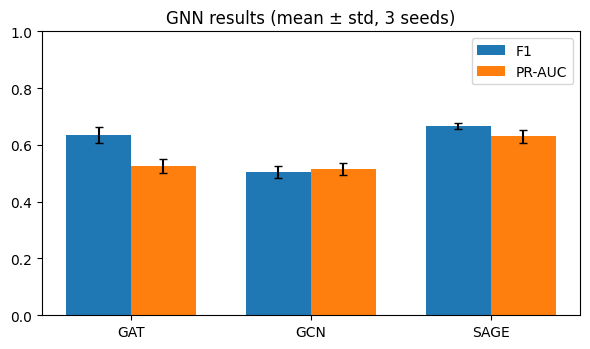

In [9]:
import matplotlib.pyplot as plt
models = list(mean.index)
x = np.arange(len(models)); w = 0.36
plt.figure(figsize=(6,3.6))
plt.bar(x-w/2, mean['F1'], w, yerr=std['F1'], label='F1', capsize=3)
plt.bar(x+w/2, mean['PR-AUC'], w, yerr=std['PR-AUC'], label='PR-AUC', capsize=3)
plt.xticks(x, models); plt.ylim(0,1); plt.legend(); plt.title('GNN results (mean ± std, 3 seeds)')
plt.tight_layout(); plt.savefig(path + 'gnn_bar.png', dpi=200); plt.show()

In [10]:
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

tr = data.train_mask.cpu().numpy(); te = data.test_mask.cpu().numpy()
X = data.x.cpu().numpy(); y = data.y.cpu().numpy()
Xtr, ytr, Xte, yte = X[tr], y[tr], X[te], y[te]
ratio = (ytr == 0).sum() / (ytr == 1).sum()

rows = []
for seed in [0, 1, 2]:
    for name, m in [('RF', RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=seed, n_jobs=-1)),
                    ('XGBOOST', XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1, scale_pos_weight=ratio, random_state=seed, eval_metric='logloss'))]:
        m.fit(Xtr, ytr)
        p = m.predict_proba(Xte)[:, 1]; pred = (p > 0.5).astype(int)
        rows.append({'Model': name, 'Precision': precision_score(yte, pred), 'Recall': recall_score(yte, pred),
                     'F1': f1_score(yte, pred), 'PR-AUC': average_precision_score(yte, p), 'ROC-AUC': roc_auc_score(yte, p)})

b = pd.DataFrame(rows)
bm = b.groupby('Model')[cols].mean(); bs = b.groupby('Model')[cols].std()
base_table = pd.DataFrame({c: [f"{bm.loc[m,c]:.3f} ± {bs.loc[m,c]:.3f}" for m in bm.index] for c in cols}, index=bm.index)
final = pd.concat([base_table, gnn_table])
final.to_csv(path + 'final_results.csv')
final

,Precision,Recall,F1,PR-AUC,ROC-AUC
Model,,,,,
RF,0.988 ± 0.002,0.689 ± 0.008,0.812 ± 0.006,0.794 ± 0.001,0.932 ± 0.002
XGBOOST,0.867 ± 0.000,0.733 ± 0.000,0.794 ± 0.000,0.800 ± 0.000,0.926 ± 0.000
GAT,0.657 ± 0.065,0.618 ± 0.007,0.636 ± 0.028,0.526 ± 0.025,0.902 ± 0.002
GCN,0.484 ± 0.048,0.528 ± 0.013,0.504 ± 0.020,0.516 ± 0.021,0.839 ± 0.002
SAGE,0.720 ± 0.023,0.619 ± 0.002,0.666 ± 0.011,0.630 ± 0.022,0.907 ± 0.001


In [11]:
class GNN(torch.nn.Module):
    def __init__(self, in_dim, hidden=64, kind='sage', layers=2):
        super().__init__()
        Conv = {'gcn': GCNConv, 'sage': SAGEConv, 'gat': GATConv}[kind]
        dims = [in_dim] + [hidden] * layers
        self.convs = torch.nn.ModuleList([Conv(dims[i], dims[i+1]) for i in range(layers)])
        self.out = torch.nn.Linear(hidden, 2)

    def embed(self, x, edge_index):
        for conv in self.convs:
            x = F.relu(conv(x, edge_index))
            x = F.dropout(x, 0.3, training=self.training)
        return x

    def forward(self, x, edge_index):
        return self.out(self.embed(x, edge_index))


In [12]:
def train_gnn(kind, epochs=200, hidden=64, lr=0.005, seed=42, layers=2):
    torch.manual_seed(seed)
    model = GNN(data.num_features, hidden, kind, layers).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=5e-4)

    n_fraud = (data.y[data.train_mask] == 1).sum().item()
    n_legit = (data.y[data.train_mask] == 0).sum().item()
    weights = torch.tensor([1.0, n_legit / n_fraud]).to(device)

    for epoch in range(epochs):
        model.train()
        opt.zero_grad()
        out = model(data.x, data.edge_index)
        loss = F.cross_entropy(out[data.train_mask], data.y[data.train_mask], weight=weights)
        loss.backward()
        opt.step()

    model.eval()
    with torch.no_grad():
        out = model(data.x, data.edge_index)
        prob = F.softmax(out, dim=1)[:, 1][data.test_mask].cpu().numpy()
    y_true = data.y[data.test_mask].cpu().numpy()
    pred = (prob > 0.5).astype(int)

    row = {
        'Model': kind.upper(), 'Layers': layers, 'Seed': seed,
        'Precision': precision_score(y_true, pred),
        'Recall': recall_score(y_true, pred),
        'F1': f1_score(y_true, pred),
        'PR-AUC': average_precision_score(y_true, prob),
        'ROC-AUC': roc_auc_score(y_true, prob),
    }
    return model, row

In [13]:
print(device, torch.cuda.is_available())

cuda True


In [16]:
BEST = 3   # change to the layer count with the best mean F1 in lay_sum

model_h, _ = train_gnn('sage', layers=BEST, seed=42)
model_h.eval()
with torch.no_grad():
    emb = model_h.embed(data.x, data.edge_index).cpu().numpy()

Xh_tr = np.hstack([X[tr], emb[tr]])
Xh_te = np.hstack([X[te], emb[te]])
hyb = XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1,
                    scale_pos_weight=ratio, random_state=42, eval_metric='logloss').fit(Xh_tr, ytr)
p_h = hyb.predict_proba(Xh_te)[:, 1]
pred = (p_h > 0.5).astype(int)
print({'Precision': round(precision_score(yte, pred), 3), 'Recall': round(recall_score(yte, pred), 3),
       'F1': round(f1_score(yte, pred), 3), 'PR-AUC': round(average_precision_score(yte, p_h), 3),
       'ROC-AUC': round(roc_auc_score(yte, p_h), 3)})

{'Precision': 0.863, 'Recall': 0.593, 'F1': 0.703, 'PR-AUC': np.float64(0.702), 'ROC-AUC': np.float64(0.861)}


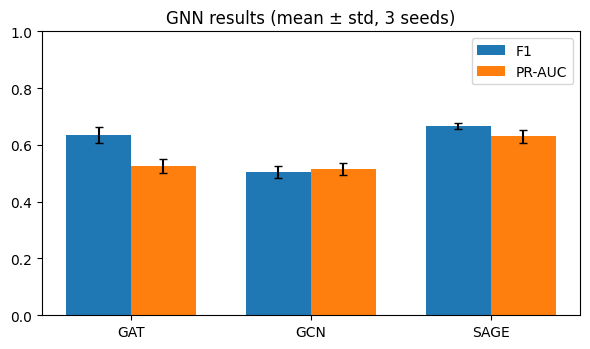

In [18]:
import matplotlib.pyplot as plt
models = list(mean.index)
x_pos = np.arange(len(models)); w = 0.36
plt.figure(figsize=(6, 3.6))
plt.bar(x_pos - w/2, mean['F1'], w, yerr=std['F1'], label='F1', capsize=3)
plt.bar(x_pos + w/2, mean['PR-AUC'], w, yerr=std['PR-AUC'], label='PR-AUC', capsize=3)
plt.xticks(x_pos, models); plt.ylim(0, 1); plt.legend()
plt.title('GNN results (mean ± std, 3 seeds)')
plt.tight_layout(); plt.savefig(path + 'gnn_bar.png', dpi=200); plt.show()

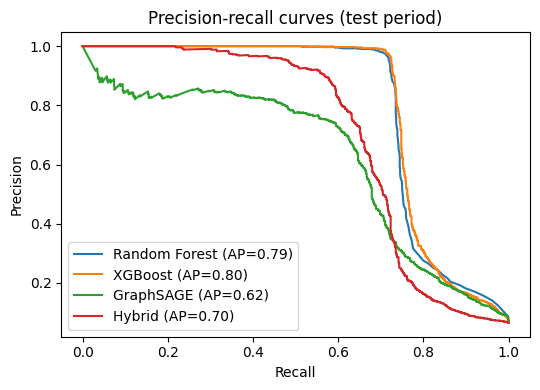

In [20]:
from sklearn.metrics import precision_recall_curve

rf = RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42, n_jobs=-1).fit(Xtr, ytr)
xg = XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1, scale_pos_weight=ratio,
                   random_state=42, eval_metric='logloss').fit(Xtr, ytr)
model_s, _ = train_gnn('sage', layers=2, seed=42)
model_s.eval()
with torch.no_grad():
    p_s = F.softmax(model_s(data.x, data.edge_index), 1)[:, 1][data.test_mask].cpu().numpy()

curves = {'Random Forest': rf.predict_proba(Xte)[:, 1], 'XGBoost': xg.predict_proba(Xte)[:, 1],
          'GraphSAGE': p_s, 'Hybrid': p_h}
plt.figure(figsize=(5.5, 4))
for name, p in curves.items():
    pr, rc, _ = precision_recall_curve(yte, p)
    plt.plot(rc, pr, label=f"{name} (AP={average_precision_score(yte, p):.2f})")
plt.xlabel('Recall'); plt.ylabel('Precision'); plt.legend()
plt.title('Precision-recall curves (test period)')
plt.tight_layout(); plt.savefig(path + 'pr_curves.png', dpi=200); plt.show()

In [22]:
import os, time
f = path + 'layers_3seeds_runs.csv'
done = pd.read_csv(f) if os.path.exists(f) else pd.DataFrame()
rows = done.to_dict('records')

for L in [1, 2, 3, 4]:
    for seed in [0, 1, 2]:
        if len(done) and ((done['Layers'] == L) & (done['Seed'] == seed)).any():
            continue
        t = time.time()
        _, r = train_gnn('sage', layers=L, seed=seed)
        rows.append(r)
        pd.DataFrame(rows).to_csv(f, index=False)
        print(f"layers={L} seed={seed} F1={r['F1']:.3f} ({time.time()-t:.0f}s)")

lay = pd.DataFrame(rows)
lay_sum = lay.groupby('Layers')[['Precision','Recall','F1','PR-AUC']].agg(['mean','std']).round(3)
lay_sum.to_csv(path + 'layers_3seeds.csv')
lay_sum

Precision        Recall            F1        PR-AUC       
            mean    std   mean    std   mean    std   mean    std
Layers                                                           
1          0.542  0.009  0.649  0.019  0.590  0.008  0.599  0.021
2          0.706  0.053  0.622  0.007  0.661  0.019  0.623  0.019
3          0.744  0.042  0.586  0.018  0.655  0.015  0.623  0.031
4          0.820  0.023  0.575  0.031  0.675  0.014  0.674  0.024

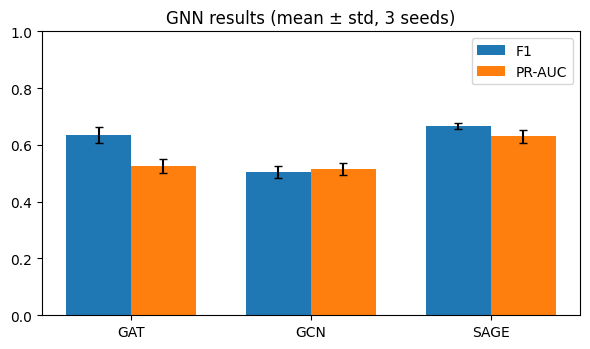

In [23]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
path = '/content/drive/MyDrive/gnn-project/data/elliptic_bitcoin_dataset/'
runs = pd.read_csv(path + 'gnn_runs.csv')
m = runs.groupby('Model')[['F1','PR-AUC']].mean()
s = runs.groupby('Model')[['F1','PR-AUC']].std()

x = np.arange(len(m)); w = 0.36
plt.figure(figsize=(6, 3.6))
plt.bar(x - w/2, m['F1'], w, yerr=s['F1'], label='F1', capsize=3)
plt.bar(x + w/2, m['PR-AUC'], w, yerr=s['PR-AUC'], label='PR-AUC', capsize=3)
plt.xticks(x, m.index); plt.ylim(0, 1); plt.legend()
plt.title('GNN results (mean ± std, 3 seeds)')
plt.tight_layout(); plt.savefig(path + 'gnn_bar.png', dpi=200); plt.show()

Each curve shows what happens as you lower the bar for calling something fraud. Moving right catches more fraud (higher recall) but usually adds false alarms (lower precision). A curve that stays high and to the right is better.

Curve	What it shows
Random Forest and XGBoost	Precision stays near 1.0 until recall reaches about 0.7. They can catch roughly 70% of fraud with almost no false alarms
Hybrid	Stays high until recall of about 0.4, then falls earlier. Better than GraphSAGE, worse than the baselines
GraphSAGE	Plateaus around 0.8 precision, so it makes more false alarms at every recall level
Three things worth noting in your report
All four curves fall steeply at recall of about 0.7 to 0.75. After that, precision collapses to about 0.1 to 0.3 for every model. So roughly a quarter of the illicit transactions in the test period look like normal ones to all of them. This suggests a ceiling set by the data. A possible cause is that fraud patterns in later time steps differ from the training period, but you haven't tested that. You can check it by computing F1 per test time step.
GraphSAGE's curve starts with a dip at very low recall (precision about 0.75 at recall of about 0.03). Some of its most confident predictions are wrong, whereas the tree models' most confident predictions are right.
The curves run into each other at high recall. All models end near the base rate, which is about 6.5% fraud in the test period, so none of them can reliably catch the last few percent of fraud.